In [1]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_DIR = "./content/plateful"



FILES = {
    "orders": "orders.csv",
    "order_status_events": "order_status_events.csv",
    "order_lines": "order_lines.csv",
    "payments": "payments.csv",
    "restaurants": "restaurants.csv",
    "customers": "customers.csv",
}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}.")

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))
payments = tables["payments"]
restaurants = tables["restaurants"]
orders = tables["orders"]
customers = tables["customers"]

orders: 14,494 rows, 5 columns
    ['order_id', 'customer_id', 'restaurant_id', 'order_ts', 'delivery_fee']
order_status_events: 56,812 rows, 4 columns
    ['event_id', 'order_id', 'status', 'event_ts']
order_lines: 36,120 rows, 5 columns
    ['order_id', 'line_no', 'item_name', 'quantity', 'unit_price']
payments: 16,423 rows, 5 columns
    ['payment_id', 'order_id', 'payment_type', 'amount', 'paid_at']
restaurants: 67 rows, 5 columns
    ['restaurant_id', 'restaurant_name', 'cuisine', 'city', 'effective_from']
customers: 4,200 rows, 3 columns
    ['customer_id', 'signup_date', 'home_city']


#### What columns do we have/need to answer the question?

In [2]:
for key, val in tables.items():
    print(f"========= {key} =========")
    display(val.head(3))

========= orders =========


,order_id,customer_id,restaurant_id,order_ts,delivery_fee
0,O000001,C01161,R052,2026-03-01T09:13:23Z,1.49
1,O000002,C00723,R027,2026-03-01T09:15:33Z,2.49
2,O000003,C00781,R044,2026-03-01T09:23:42Z,0.00


========= order_status_events =========


,event_id,order_id,status,event_ts
0,E027809,O007104,accepted,2026-04-29T13:28:57Z
1,E018209,O004658,placed,2026-04-08T19:11:30Z
2,E043792,O011178,accepted,2026-06-02T17:07:47Z


========= order_lines =========


,order_id,line_no,item_name,quantity,unit_price
0,O000001,1,Ramen,3,12.0
1,O000002,1,Soft drink,1,2.0
2,O000002,2,Side salad,1,3.5


... (2 outputs left out)

========= restaurants =========


,restaurant_id,restaurant_name,cuisine,city,effective_from
0,R064,Fresh Vegan 64,Vegan,London,2025-01-01
1,R012,Royal Burgers 12,Burgers,Bristol,2025-01-01
2,R028,Grand Burgers 28,Burgers,Birmingham,2025-01-01


========= customers =========


,customer_id,signup_date,home_city
0,C00001,2024-10-15,London
1,C00002,2025-05-17,Leeds
2,C00003,2026-01-25,Leeds


### Data Cleaning

#### Overall / Everything

In [3]:

print("========================")
for column in customers.columns:
    print(f"{column}: Missing {customers[column].isna().sum()} values out of {customers.shape[0]}")
print("========================")
# We only care about XXX so missing values rows
customers = customers.dropna(subset=["customer_id"])
# BE CAREFUL LIKELY NOT USED
customers["signup_date"] = customers["signup_date"].ffill()
customers["home_city"] = customers["home_city"].fillna("Woking")

for column in customers.columns:
    print(f"{column}: Missing {customers[column].isna().sum()} values out of {customers.shape[0]}")

customer_id: Missing 2 values out of 4200
signup_date: Missing 1 values out of 4200
home_city: Missing 2 values out of 4200
customer_id: Missing 0 values out of 4198
signup_date: Missing 0 values out of 4198
home_city: Missing 0 values out of 4198


#### ID

In [4]:
# Duplicates
duplicate_ids = payments[
    payments.duplicated(subset=["payment_id"], keep=False)
    ].sort_values(by="payment_id")
display(duplicate_ids)

,payment_id,order_id,payment_type,amount,paid_at
5949,P000219,O000185,charge,25.49,2026-03-02 19:05:43
13373,P000219,O000185,charge,25.49,2026-03-02 19:05:43
1673,P000927,O000815,charge,23.99,2026-03-08 11:53:53
4665,P000927,O000815,charge,23.99,2026-03-08 11:53:53
6582,P000998,O000874,charge,50.99,2026-03-08 19:19:26
3747,P000998,O000874,charge,50.99,2026-03-08 19:19:26
975,P001859,O001631,charge,38.49,2026-03-14 22:43:50
5224,P001859,O001631,charge,38.49,2026-03-14 22:43:50
15431,P002189,O001926,charge,41.99,2026-03-17 18:22:24
9230,P002189,O001926,charge,41.99,2026-03-17 18:22:24


In [5]:
print(f"XXX shape inc duplicates: {payments.shape}")
payments = payments.drop_duplicates() # Keep to decide method
print(f"XXX shape exc duplicates: {payments.shape}")

XXX shape inc duplicates: (16423, 5)
XXX shape exc duplicates: (16393, 5)


#### Categorical

In [6]:
print(f"Unique Values {list(restaurants["city"].unique())}")
restaurants["city"] = (
    restaurants["city"]
    .str.replace(r'[\s|_]+', ' ', regex=True)
    .str.strip()
    .str.title()
    )
print(f"Unique Values {list(restaurants["city"].unique())}")


Unique Values ['London', 'Bristol', 'Birmingham', 'LEEDS', 'Manchester', 'MANCHESTER', 'Leeds', 'LONDON']
Unique Values ['London', 'Bristol', 'Birmingham', 'Leeds', 'Manchester']


#### Continuous

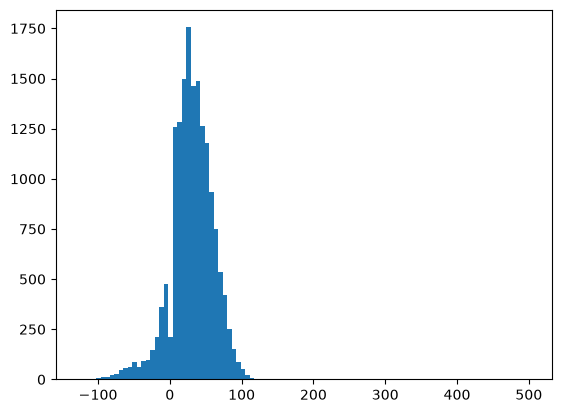

========= Max Values ============


,payment_id,order_id,payment_type,amount,paid_at
14,P008386,O007403,charge,500.50,2026-05-01 20:52:51
16378,P013253,O011718,charge,127.49,2026-06-07 11:35:21
15446,P015310,O013532,charge,123.99,2026-06-22 19:21:39
6877,P000224,O000190,charge,120.99,2026-03-02 19:14:58
15719,P014791,O013068,charge,120.49,2026-06-19 13:09:23
6485,P008491,O007491,charge,119.99,2026-05-02 17:41:41
7014,P009345,O008253,charge,117.99,2026-05-09 11:54:11
4860,P010432,O009207,charge,116.99,2026-05-17 11:02:26
3951,P001149,O001007,charge,116.99,2026-03-09 20:17:55
9365,P006934,O006133,charge,116.99,2026-04-20 19:04:20


========= Min Values ============


,payment_id,order_id,payment_type,amount,paid_at
629,P013254,O011718,refund,-127.49,2026-06-07 11:39:39
6313,P016298,O014407,refund,-105.99,2026-06-30 11:27:03
14174,P002327,O002048,refund,-102.99,2026-03-18 19:23:07
5306,P002191,O001927,refund,-101.99,2026-03-17 18:41:53
14391,P005682,O005025,refund,-101.99,2026-04-11 18:34:00
3458,P012606,O011142,refund,-101.49,2026-06-02 10:51:43
12289,P015868,O014025,refund,-100.99,2026-06-27 11:16:56
15770,P008028,O007096,refund,-99.50,2026-04-29 12:53:35
2535,P015313,O013534,refund,-98.49,2026-06-22 19:37:29
13083,P007468,O006600,refund,-98.49,2026-04-24 23:10:28


In [7]:
!pip install matplotlib --quiet

import matplotlib.pyplot as plt
plt.hist(payments["amount"],bins=100)
plt.show()
print("========= Max Values ============")
display(payments.sort_values(by="amount",ascending=False).head(30))
print("========= Min Values ============")
display(payments.sort_values(by="amount").head(30))



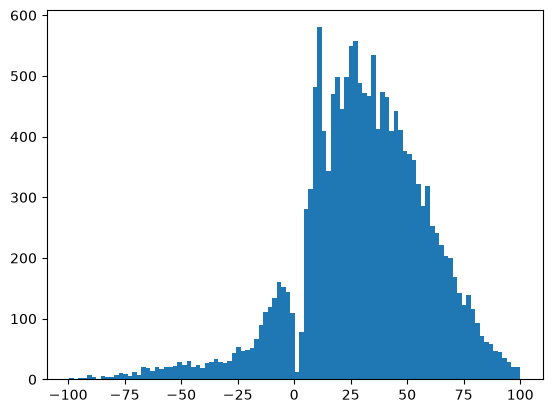

In [8]:
# USE BACKETS
payments = payments[
    (payments["amount"] < 100) & (payments["amount"] > -100)
]
plt.hist(payments["amount"],bins=100)
plt.show()

#### Times / Dates


In [9]:

# https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#timeseries-offset-aliases
# Set to midnight
midnights = pd.to_datetime(payments["paid_at"]).dt.normalize()
weeks = pd.to_datetime(payments["paid_at"]).dt.to_period("W").dt.start_time 
months = pd.to_datetime(payments["paid_at"]).dt.to_period("M")
diff = (midnights - weeks).dt.total_seconds()
print(diff)

# https://docs.python.org/3/library/datetime.html#strftime-and-strptime-behavior


0        259200.0
1         86400.0
2        172800.0
3        518400.0
4             0.0
           ...   
16418    345600.0
16419     86400.0
16420    432000.0
16421     86400.0
16422    345600.0
Name: paid_at, Length: 16311, dtype: float64


#### Ordinal Data

In [10]:
# See categorical
df = pd.DataFrame({
    'Satisfaction': ['High', 'Low', 'Medium', 'High', 'Low']
})

df['Satisfaction'] = pd.Categorical(
    df['Satisfaction'],
    categories=['Low', 'Medium', 'High'],
    ordered=True
)

df["more_than_medium"] = df["Satisfaction"] >= "Medium"
df = df.sort_values(by="Satisfaction")
display(df)

,Satisfaction,more_than_medium
1,Low,False
4,Low,False
2,Medium,True
0,High,True
3,High,True
